In [2]:
import sqlite3 as sql

In [3]:
conn=sql.connect('hospital_data.db')
cursor=conn.cursor()
with open('create_hospital_db.sql','r',encoding='utf-8-sig') as file:
    queries=file.read()

In [4]:
# for i in queries.split(';'):
#     if not(i.startswith('--')):
#         cursor.executescript(i)
#         conn.commit()

In [5]:
import pandas as pd
pd.read_sql('select * from payers;',conn)

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244,1-877-267-2323
1,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare,7500 Security Blvd,Baltimore,MD,21244,1-800-633-4227
2,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,Medicaid,7500 Security Blvd,Baltimore,MD,21244,1-877-267-2323
3,d47b3510-2895-3b70-9897-342d681c769d,Humana,500 West Main St,Louisville,KY,40018,1-844-330-7799
4,6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield,Michigan Plaza,Chicago,IL,60007,1-800-262-2583
5,5059a55e-5d6e-34d1-b6cb-d83d16e57bcf,UnitedHealthcare,9800 Healthcare Lane,Minnetonka,MN,55436,1-888-545-5205
6,4d71f845-a6a9-3c39-b242-14d25ef86a8d,Aetna,151 Farmington Ave,Hartford,CT,06156,1-800-872-3862
7,047f6ec3-6215-35eb-9608-f9dda363a44c,Cigna Health,900 Cottage Grove Rd,Bloomfield,CT,06002,1-800-997-1654
8,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Anthem,220 Virginia Ave,Indianapolis,IN,46204,1-800-331-1476
9,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE,None,None,None,None,None


In [6]:
pay=pd.read_sql('select * from payers;',conn)
pat=pd.read_sql('select * from patients;',conn)
enc=pd.read_sql('select * from encounters;',conn)

In [7]:
dfs=[('Payers',pay),('Patients',pat),('Encountrers',enc)]

In [8]:
for N,i in dfs:
    print(N,i.shape)

Payers (10, 7)
Patients (973, 20)
Encountrers (27891, 14)


In [9]:
for N,i in dfs:
    print(N,'=>',i.columns)

Payers => Index(['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE_HEADQUARTERED', 'ZIP', 'PHONE'], dtype='object')
Patients => Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX',
       'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE',
       'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON'],
      dtype='object')
Encountrers => Index(['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER',
       'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='object')


In [10]:
for N ,df in  dfs:
    print('Statical info  for numeric Data')
    print(N)
    print(df.describe().T)
    print('Statistical Info for Catagorical Data')
    print(N)
    print(df.describe(include='object').T)

Statical info  for numeric Data
Payers
                    count unique                                   top freq
Id                     10     10  b3221cfc-24fb-339e-823d-bc4136cbc4ed    1
NAME                   10     10                         Dual Eligible    1
ADDRESS                 9      7                    7500 Security Blvd    3
CITY                    9      7                             Baltimore    3
STATE_HEADQUARTERED     9      6                                    MD    3
ZIP                     9      7                                 21244    3
PHONE                   9      8                        1-877-267-2323    2
Statistical Info for Catagorical Data
Payers
                    count unique                                   top freq
Id                     10     10  b3221cfc-24fb-339e-823d-bc4136cbc4ed    1
NAME                   10     10                         Dual Eligible    1
ADDRESS                 9      7                    7500 Security Blvd    3
CITY

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

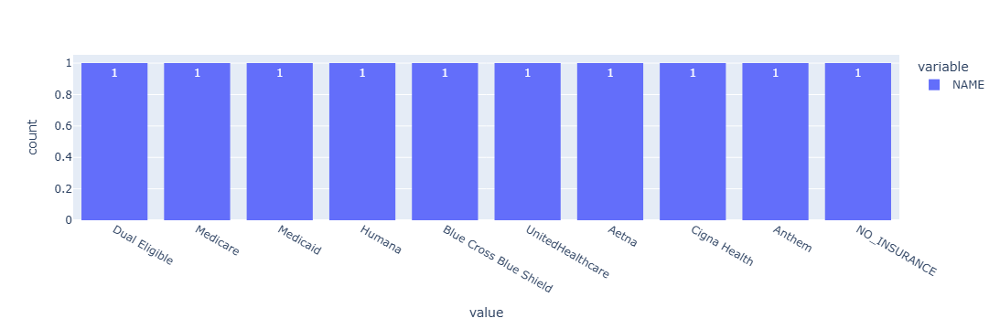

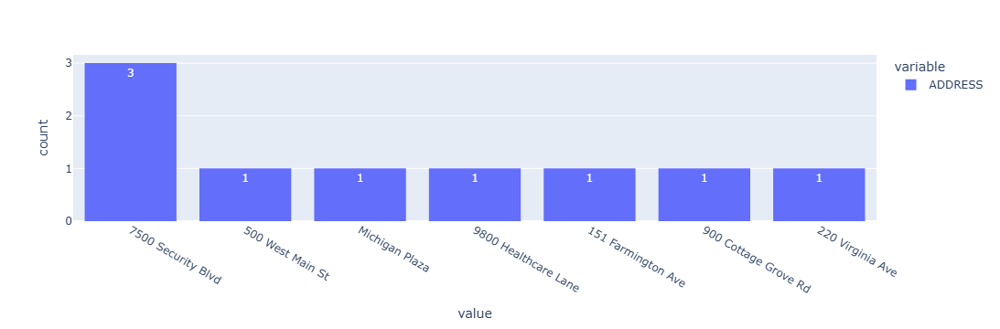

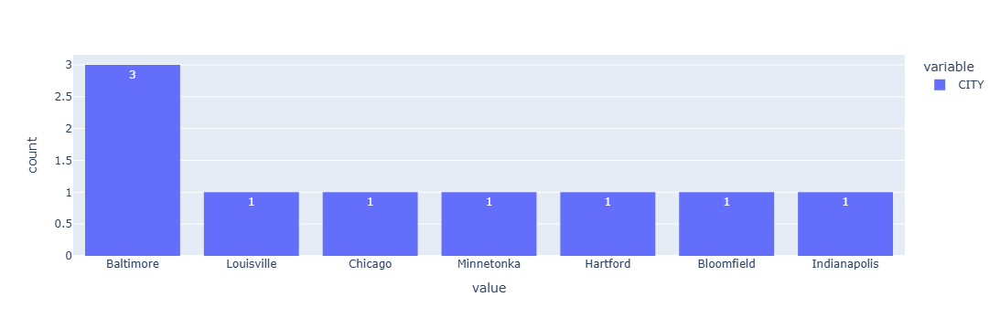

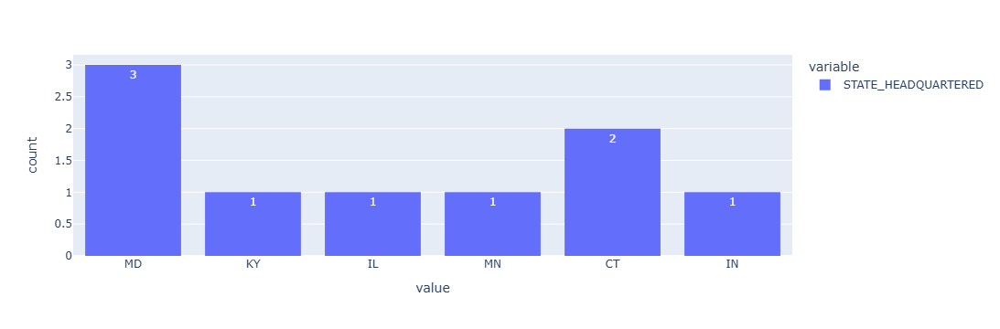

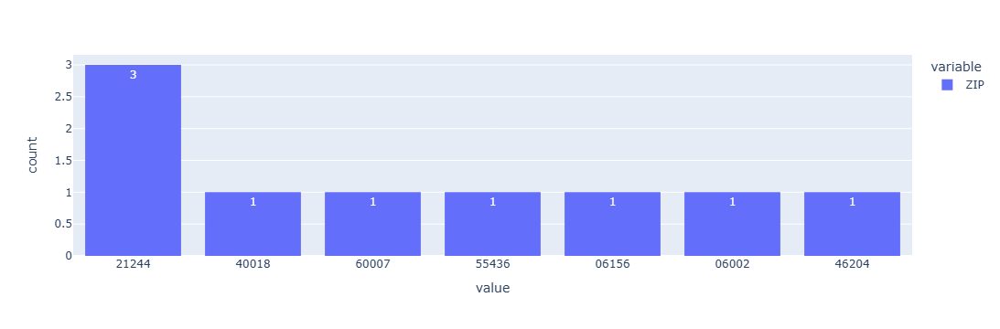

...

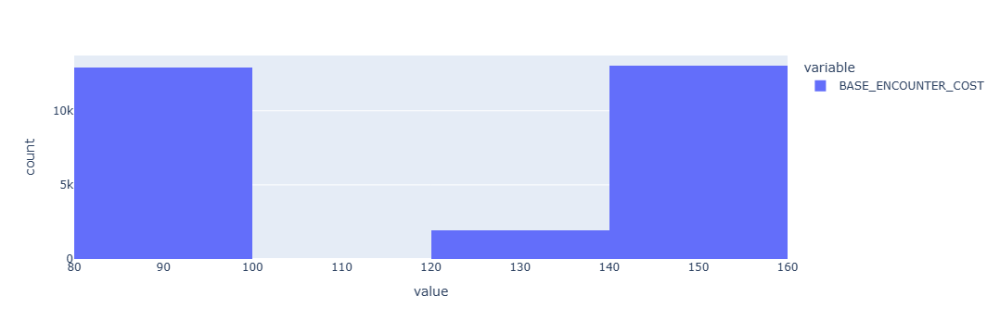

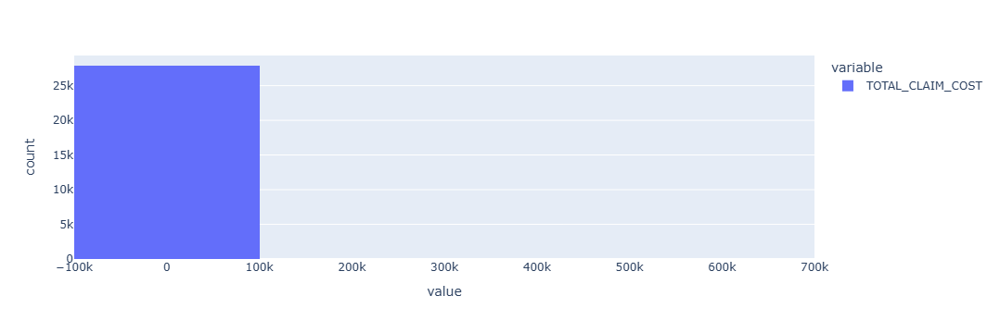

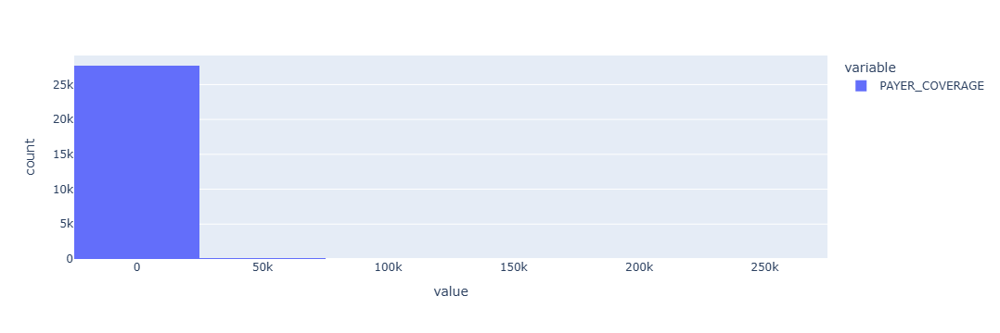

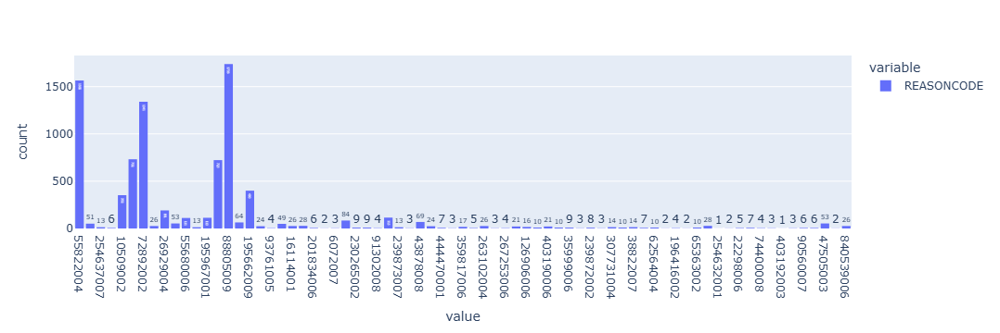

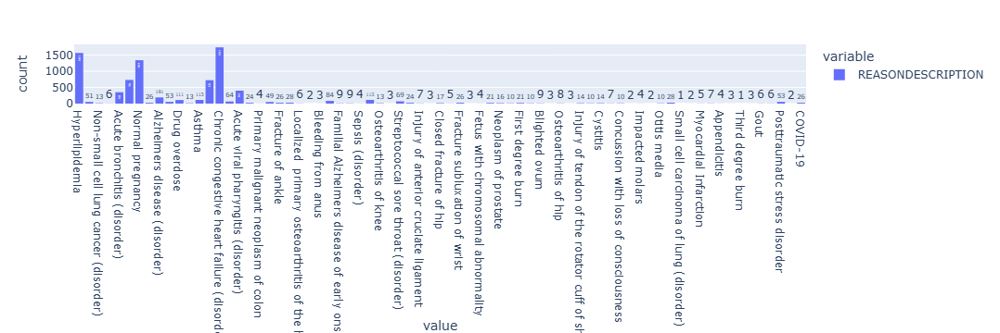

In [13]:
for N,df in dfs:
    for col in df.columns:
        if df[col].dtypes!='object' and 'id' not in col.lower():
            fig=px.histogram(df[col],nbins=5)
            fig.show()
        elif df[col].dtypes=='object' and 'id' not in col.lower():
            fig=px.histogram(df[col],text_auto=True)
            fig.show()

In [14]:
dfs[0][1].dtypes # do not draw boxplot because are mainly use as outlayers.

Id                     object
NAME                   object
ADDRESS                object
CITY                   object
STATE_HEADQUARTERED    object
ZIP                    object
PHONE                  object
dtype: object

In [15]:
dfs[1][1].dtypes

Id             object
BIRTHDATE      object
DEATHDATE      object
PREFIX         object
FIRST          object
LAST           object
SUFFIX         object
MAIDEN         object
MARITAL        object
RACE           object
ETHNICITY      object
GENDER         object
BIRTHPLACE     object
ADDRESS        object
CITY           object
STATE          object
COUNTY         object
ZIP            object
LAT           float64
LON           float64
dtype: object

In [16]:
dfs[2][1].dtypes

Id                      object
START                   object
STOP                    object
PATIENT                 object
ORGANIZATION            object
PAYER                   object
ENCOUNTERCLASS          object
CODE                    object
DESCRIPTION             object
BASE_ENCOUNTER_COST    float64
TOTAL_CLAIM_COST       float64
PAYER_COVERAGE         float64
REASONCODE              object
REASONDESCRIPTION       object
dtype: object

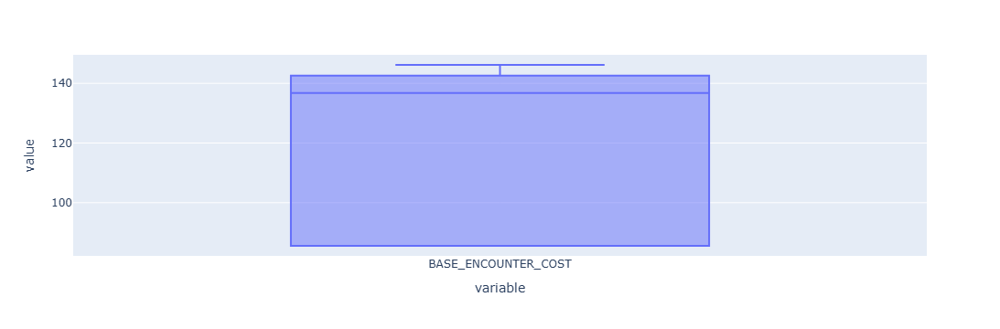

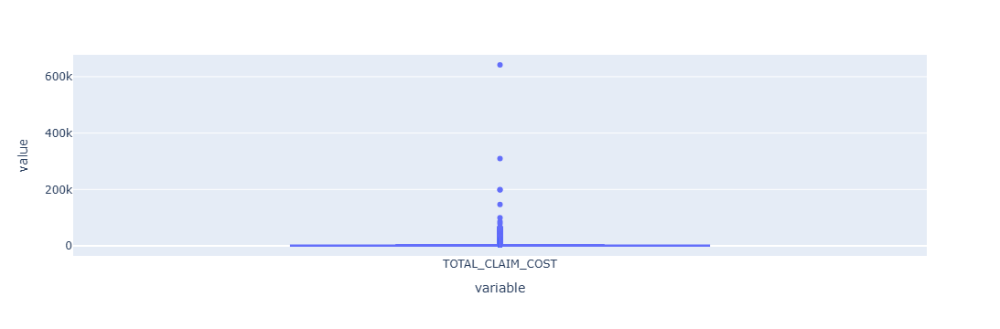

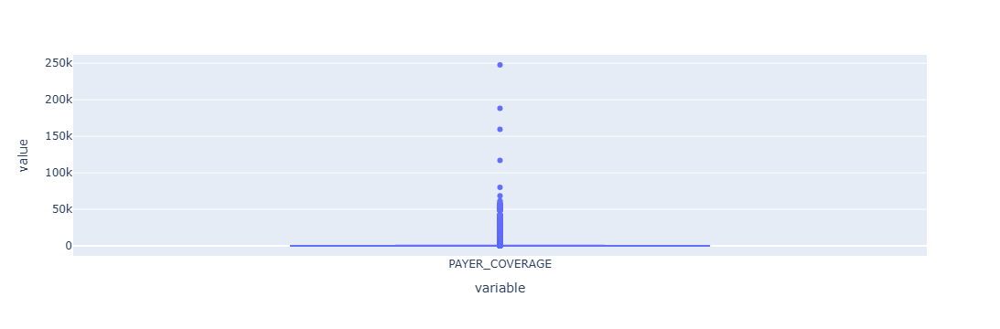

In [17]:
for i in dfs[2][1].columns:
    if dfs[2][1][i].dtypes!='object':
        fig=px.box(dfs[2][1][i])
        fig.show()

In [18]:
dfs[2][1].columns

Index(['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER',
       'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='object')

In [19]:
Paydf=dfs[2][1][['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST', 'PAYER_COVERAGE']]

In [20]:
Paydf=pd.melt(
    Paydf,
    value_vars=['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST','PAYER_COVERAGE']
).rename(columns={'variable':'Cost_category','value':'cost'})

In [21]:
Paydf=Paydf.groupby('Cost_category').agg({'cost':'sum'}).reset_index().sort_values('cost',ascending=True)

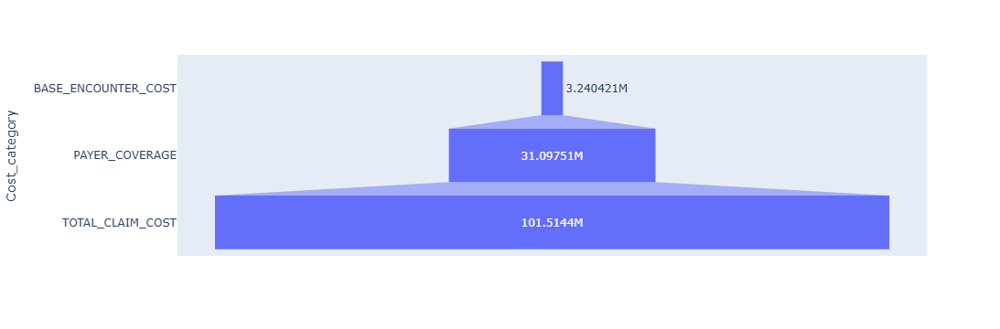

In [22]:
px.funnel(
    Paydf,
    x='cost',
    y='Cost_category'
)

In [23]:
 dfs[2][1].describe().T

,count,mean,std,min,25%,50%,75%,max
BASE_ENCOUNTER_COST,27891.0,116.181614,28.410082,85.55,85.55,136.80,142.58,146.18
TOTAL_CLAIM_COST,27891.0,3639.682174,9205.595748,0.00,142.58,278.58,1412.53,641882.70
PAYER_COVERAGE,27891.0,1114.965652,4768.615576,0.00,0.00,28.44,155.77,247751.42


In [24]:
dfs[0][1].describe(include='object').T

,count,unique,top,freq
Id,10,10,b3221cfc-24fb-339e-823d-bc4136cbc4ed,1
NAME,10,10,Dual Eligible,1
ADDRESS,9,7,7500 Security Blvd,3
CITY,9,7,Baltimore,3
STATE_HEADQUARTERED,9,6,MD,3
ZIP,9,7,21244,3
PHONE,9,8,1-877-267-2323,2


In [25]:
dfs[1][1].describe(include='object').T

,count,unique,top,freq
Id,973,973,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1
BIRTHDATE,973,879,1925-11-17,4
DEATHDATE,0,0,NaN,NaN
PREFIX,973,3,Mr.,494
FIRST,973,841,Franklyn361,3
LAST,973,498,Heaney114,6
SUFFIX,0,0,NaN,NaN
MAIDEN,973,280,,588
MARITAL,973,3,M,783
RACE,973,6,white,679


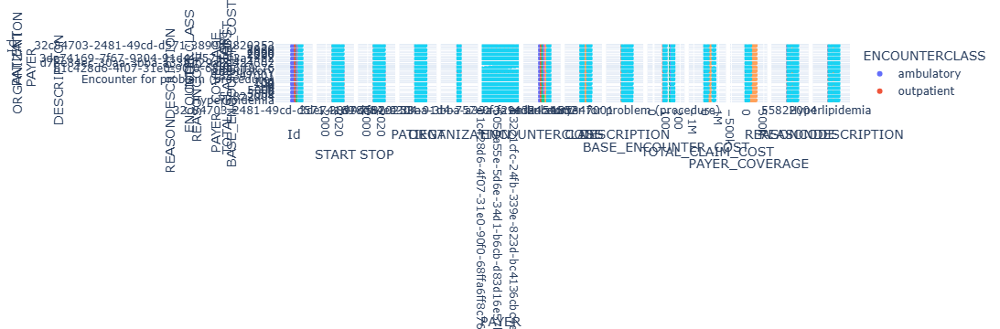

In [26]:
px.scatter_matrix(dfs[2][1],color='ENCOUNTERCLASS')

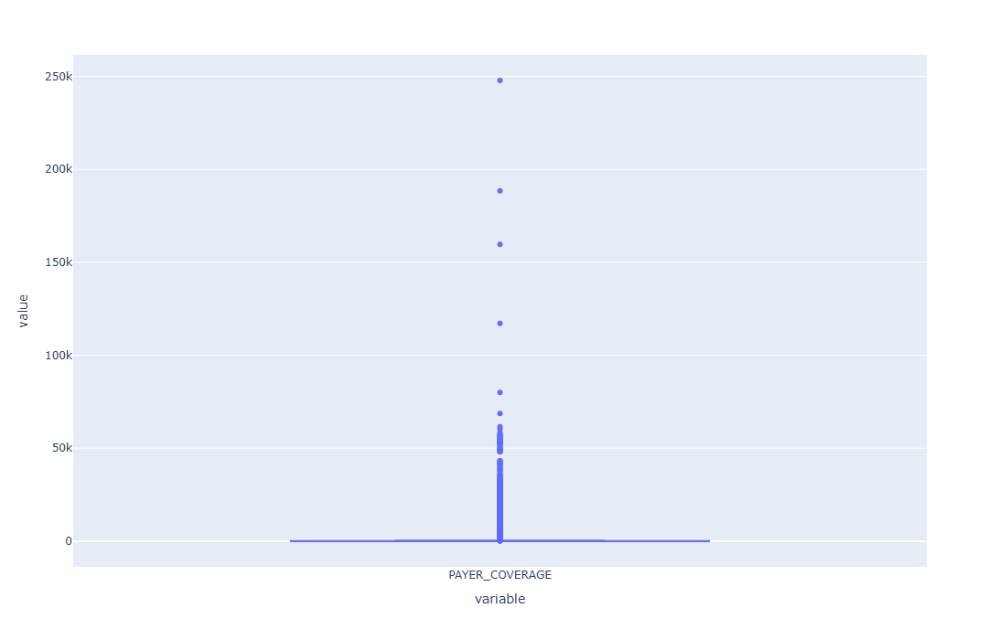

In [27]:
px.scatter_matrix(dfs[2][1],dimensions=['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST','PAYER_COVERAGE'],color='ENCOUNTERCLASS')
fig.update_layout(
    width=700,
    height=700
)

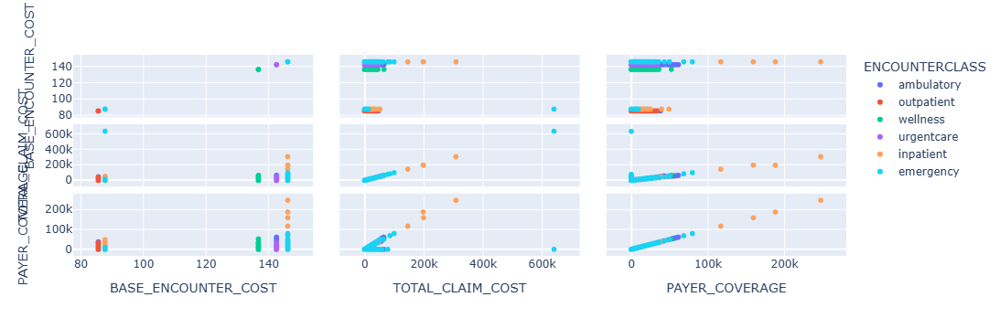

In [28]:
px.scatter_matrix(dfs[2][1],dimensions=['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST','PAYER_COVERAGE'],color='ENCOUNTERCLASS')

In [29]:
print('Total Insurance companies : ',len(dfs[0][1]['NAME'].unique())-1)

Total Insurance companies :  9


In [30]:
dfs[0][1].head(1)

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244,1-877-267-2323


In [31]:
BD=pd.to_datetime(dfs[1][1]['BIRTHDATE'])

In [32]:
import datetime as dt

In [33]:
Age=(dt.datetime.now().year - BD.dt.year).astype('int8')

In [34]:
print('Average age of a Patient :',round(Age.mean(),0))

Average age of a Patient : 74.0


In [35]:
round((dfs[1][1]['GENDER'].value_counts()/(494+497))*100,0)

GENDER
M    50.0
F    48.0
Name: count, dtype: float64

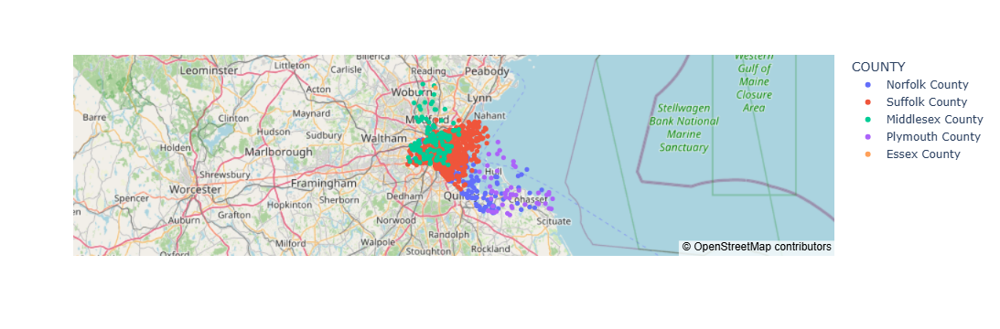

In [36]:
px.scatter_map(
    dfs[1][1],
    lat='LAT',
    lon='LON',
    hover_name='STATE',
    color='COUNTY',
    map_style='open-street-map'
)

# Dashboard

In [37]:
# Total Patients
dfs[1][1]['Id'].nunique()

973

In [38]:
dfs[2][1]['START']=pd.to_datetime(dfs[2][1]['START'])
dfs[2][1]['STOP']=pd.to_datetime(dfs[2][1]['STOP'])

In [39]:
Time_wise_patients=dfs[2][1].groupby(
    [dfs[2][1]['START'].dt.year,dfs[2][1]['START'].dt.month]).agg(
    {'PATIENT':'nunique'}
    )

In [40]:
This_month=Time_wise_patients.iloc[-2,-1]
Last_month=Time_wise_patients.iloc[-3,-1]
Growth=((This_month/Last_month)-1)*100
print(str(round(Growth))+'%')

-6%


In [41]:
Time_wise_Encounters=dfs[2][1].groupby(
    [dfs[2][1]['START'].dt.year,dfs[2][1]['START'].dt.month]).agg(
        {'Id':'nunique'})

In [42]:
This_monthE=Time_wise_Encounters.iloc[-2,-1]
Last_monthE=Time_wise_Encounters.iloc[-3,-1]
GrowthE=((This_monthE/Last_monthE)-1)*100
print(str(round(GrowthE))+'%')

-5%


In [43]:
years=[i[0] for i in Time_wise_Encounters.index] # Extraction off years from iindex
month=[i[1] for i in Time_wise_Encounters.index] # Extraction of month from index

In [44]:
Time_wise_Encounters['year']=years
Time_wise_Encounters['month']=month

In [45]:
Time_wise_Encounters=Time_wise_Encounters.reset_index(drop=True)

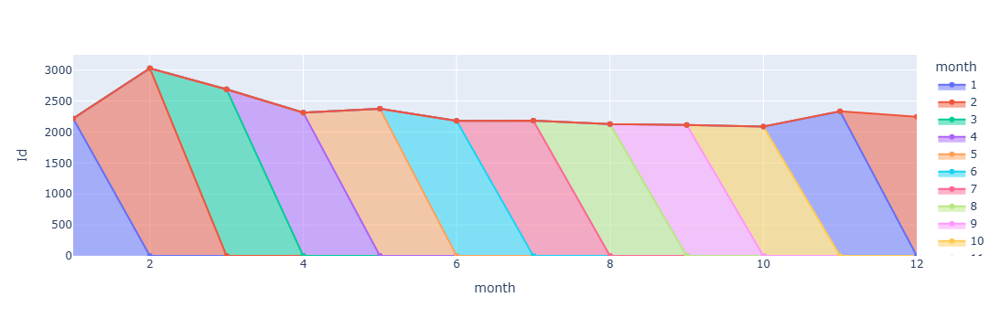

In [46]:
ME=Time_wise_Encounters.groupby('month').agg({'Id':'sum'}).reset_index()
px.area(ME,x='month',y='Id',markers='o',color='month')

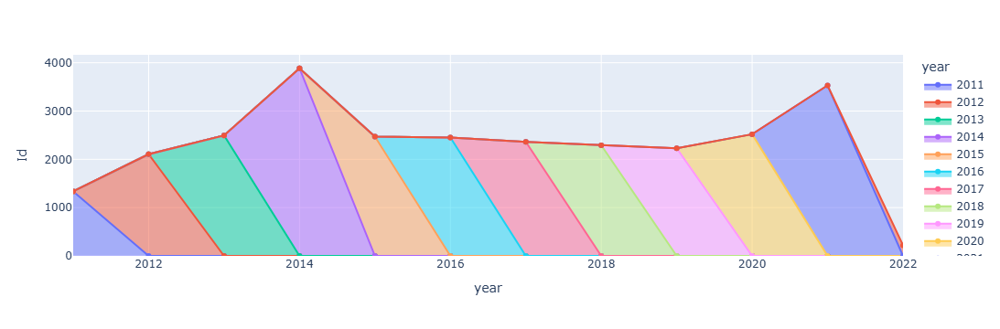

In [47]:
YE=Time_wise_Encounters.groupby('year').agg({'Id':'sum'}).reset_index()
px.area(YE,x='year',y='Id',markers='o',color='year')

In [48]:
from datetime import datetime as dt

In [49]:
dfs[1][1]['Age']=dt.now().year-pd.to_datetime(
    dfs[1][1]['BIRTHDATE']).dt.year

In [50]:
dfs[1][1]['Age_bin']=pd.cut(
    dfs[1][1]['Age'],
    bins=5,
    labels=['35 to 49','49 to 63','63 to 76','76 to 90','90 to 104']
)

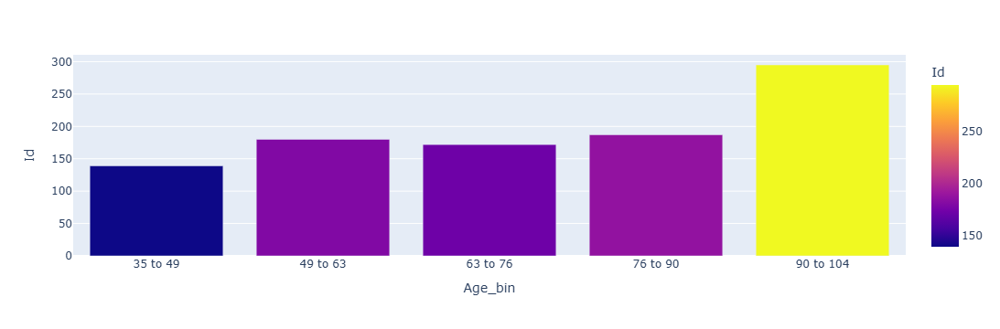

In [51]:
Age_wise_patients=dfs[1][1].groupby('Age_bin',observed=True).agg({'Id':'nunique'}).reset_index()
px.bar(Age_wise_patients,x='Age_bin',y='Id',color='Id')

In [52]:
GD=dfs[1][1]['GENDER'].value_counts().reset_index()

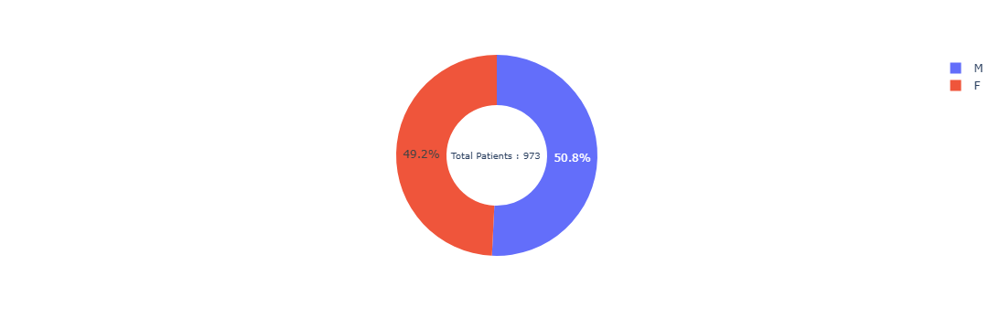

In [53]:
fig=px.pie(GD,
          names=GD['GENDER'],
          values=GD['count'],
          hole=0.5)
fig.add_annotation(
    text=f'Total Patients : {dfs[1][1]['Id'].nunique()} ',
    x=0.5,
    y=0.5,
    font_size=10,
    showarrow=False
)
fig.show()

In [54]:
dfs[2][1].head(1)['PAYER']

0    b1c428d6-4f07-31e0-90f0-68ffa6ff8c76
Name: PAYER, dtype: object

In [56]:
Payers=pd.read_csv('payers.csv')

In [57]:
Payers.head(1)

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323


In [58]:
payer=pd.merge(dfs[2][1],Payers,left_on='PAYER',right_on='Id',how='inner')

In [59]:
Top_Payers=payer.groupby('NAME').agg({'PAYER_COVERAGE':'sum'}).sort_values('PAYER_COVERAGE').iloc[::,:].reset_index()

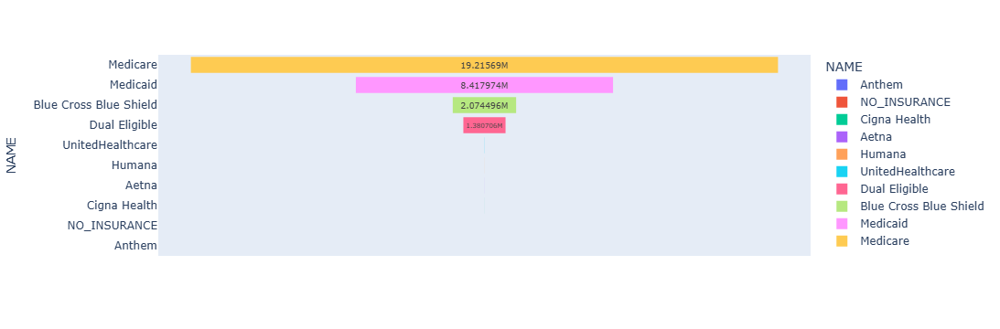

In [60]:
fig=px.funnel(Top_Payers,x='PAYER_COVERAGE',y='NAME',color='NAME')
fig.update_traces(
    textposition='inside',
    textfont_size=14
)

In [64]:
# Top Encounter Class
dfs[2][1]['DESCRIPTION']=dfs[2][1]['DESCRIPTION'].str.replace('(procedure)','')
Top_Encounters=dfs[2][1].groupby('DESCRIPTION').agg(
    {'Id':'count'}).sort_values('Id').iloc[::,:].reset_index().tail(5)

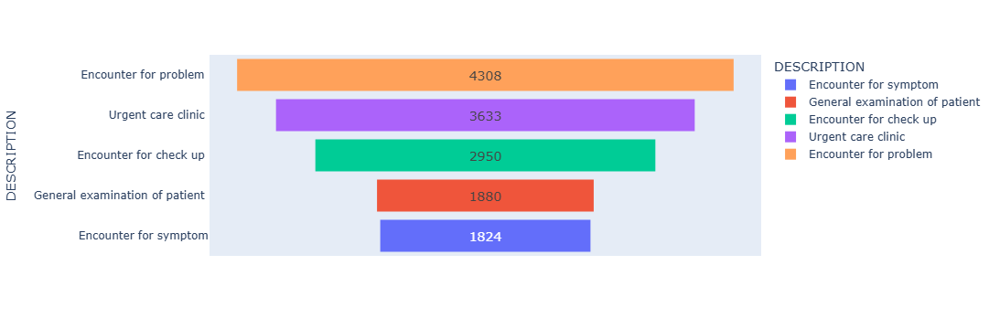

In [65]:
fig=px.funnel(Top_Encounters,x='Id',y='DESCRIPTION',color='DESCRIPTION')
fig.update_traces(
    textposition='inside',
    textfont_size=14
)

In [66]:
Desc=dfs[2][1].groupby('ENCOUNTERCLASS').agg({'Id':'count'}).reset_index().sort_values('Id').tail(5)

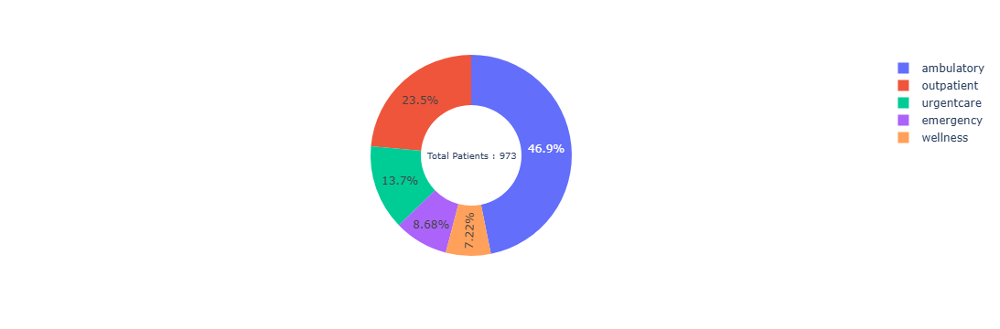

In [67]:
fig=px.pie(Desc,
           names='ENCOUNTERCLASS',
           values='Id',
           hole=0.5
)
fig.add_annotation(
    text=f'Total Patients : {dfs[1][1]['Id'].nunique()}',
    x=0.5,y=0.5,font_size=10,showarrow=False
)
fig.show()

In [68]:
# Total Patients
dfs[1][1]['Id'].nunique()

973

In [69]:
# Total Encounters
dfs[2][1]['Id'].nunique()

27891

In [70]:
# Total Insurance Payers
dfs[0][1]['Id'].nunique()

10

In [71]:
# Total Medical Procedures
dfs[2][1]['DESCRIPTION'].nunique()

53

In [72]:
# Total claim cost
'$' + str(round(dfs[2][1]['TOTAL_CLAIM_COST'].sum()/1000000)) + 'M'

'$102M'

In [73]:
# Payer Coverage
'$' + str(round(dfs[2][1]['PAYER_COVERAGE'].sum()/1000000)) + 'M'

'$31M'

In [74]:
# Patient Responsibility
'$' + str(round(dfs[2][1]['BASE_ENCOUNTER_COST'].sum()/1000000)) + 'M'

'$3M'